# 06 Camera models: does the optional camera help, and how does a small camera network compare with the magnetic coils?

**Question (REQ-B01, REQ-B03, REQ-B05; bonus items of IPP task 1).** The assignment allows a model that works from fast
camera images instead of, or together with, the 24 magnetic measurements. We trained **this small 48x64 camera network**
(a convolutional network on frames shrunk to 48x64 pixels, 811 thousand parameters) to estimate the same 16 shape targets of the institute's reference reconstruction. These targets are the output of that reconstruction, not an independent measurement of the plasma, so the camera network is judged by how closely it reproduces the reconstruction, not against the plasma itself.
Four sub-questions:

1. How closely does this small camera network reproduce the reference reconstruction on discharges it never saw, and how does that change with the number of
   training discharges (learning curve)?
2. Does color matter, or is a black and white camera enough (REQ-B03)?
3. How does it compare with a magnetic network **on the same frames and the same folds**, and does feeding it both inputs
   help (REQ-B01)?
4. How badly does it react when the camera moves (REQ-B05)?

**What this notebook does and does not use.** The IPP camera images are confidential (CON-001) and are not in git. The
networks were trained elsewhere by `analysis/cloud_camera_model.py`; this notebook only reads the **result files committed in
git** (`results/cloud-camera-*.md` and `.json`), parses the numbers from them (nothing is typed in by hand), plots them and
writes the answer from the parsed values. It touches no image and no raw row of the data. Nothing is retrained here.

**Wording rules.** We say "this small 48x64 camera network", never "the camera": a better network, a higher resolution or
more training discharges could change the result. A camera network and a magnetic network are compared **only on the same
frames and folds** (table in section 5); the baseline magnetic numbers of notebook 02 use all 149 discharges and are not a
like-for-like comparison for the camera.

In [1]:
import json, re, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

# Only files committed in git are read: the repository root is found from the results folder, and every file opened through
# load_json / load_md is recorded and checked against `git ls-files` at the end of the notebook.
here = Path.cwd().resolve()
repo = next((p for p in [here, *here.parents] if (p / "results" / "cloud-camera-main.json").exists()), None)
if repo is None:
    raise SystemExit("Run from inside the repository: results/cloud-camera-main.json was not found")
RES = repo / "results"
READ = []

def load_json(name):
    READ.append(f"results/{name}")
    return json.loads((RES / name).read_text(encoding="utf-8"))

def load_md_table(name, table_index=0):
    # first pipe table of a results .md file as a DataFrame; numbers become floats, blanks stay empty strings
    READ.append(f"results/{name}")
    blocks, cur = [], []
    for line in (RES / name).read_text(encoding="utf-8").splitlines():
        if line.startswith("|"):
            cur.append(line)
        elif cur:
            blocks.append(cur); cur = []
    if cur:
        blocks.append(cur)
    rows = [[c.strip() for c in l.strip().strip("|").split("|")] for l in blocks[table_index]]
    head, body = rows[0], [r for r in rows[2:]]
    df = pd.DataFrame(body, columns=head)
    for c in df.columns[1:]:
        if c != "unit":
            df[c] = pd.to_numeric(df[c])
    return df.set_index("target")

def load_md_line(name, prefix):
    READ.append(f"results/{name}")
    for line in (RES / name).read_text(encoding="utf-8").splitlines():
        if line.startswith(prefix):
            return line
    raise KeyError(prefix)

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})
C_MAG, C_CAM, C_BOTH, C_GREY = "#2a6fdb", "#e07a5f", "#6a994e", "#7d7d7d"
print("repository root found, results folder:", RES.name, "| camera result files in git:",
      sorted(p.name for p in RES.glob("cloud-camera-*") if p.suffix in (".md", ".json", ".png")))

repository root found, results folder: results | camera result files in git: ['cloud-camera-curve.json', 'cloud-camera-curve.md', 'cloud-camera-curve.png', 'cloud-camera-decisions.md', 'cloud-camera-findings.md', 'cloud-camera-main-sensitivity.png', 'cloud-camera-main.json', 'cloud-camera-main.md', 'cloud-camera-multimodal.json', 'cloud-camera-multimodal.md', 'cloud-camera-multimodal.png']


## 1. Protocol (read from the result files)

In [2]:
main = load_json("cloud-camera-main.json")
multi = load_json("cloud-camera-multimodal.json")
curve = load_json("cloud-camera-curve.json")
base = load_json("ipp1-baseline.json")

PROTO = {
    "image size (pixels, height x width)": main["size"],
    "frames used": main["frames"],
    "discharges with frames (of 149 in the magnetic data)": main["discharges"],
    "frame step (every n-th frame of a discharge)": main["stride"],
    "folds (split by whole discharge)": main["folds"],
    "test discharges per fold": main["test_discharges_per_fold"],
    "training epochs / network width / seed": f'{main["epochs"]} / {main["width"]} / {main["seed"]}',
    "parameters (color / gray)": f'{main["latency"]["rgb"]["parameters"]:,} / {main["latency"]["grey"]["parameters"]:,}',
}
for k, v in PROTO.items():
    print(f"{k:55s} {v}")
for name, d in (("multimodal", multi), ("curve", curve)):
    same = all(d[k] == main[k] for k in ("size", "frames", "discharges", "stride", "folds", "epochs", "width", "seed", "test_discharges_per_fold"))
    print(f"run '{name}' uses the same frames, folds and settings as 'main': {same}")
    assert same
print(f"\nmean training discharges per fold: {main['discharges']} discharges minus the test discharges of a fold, about "
      f"{curve['training']['fraction_1']['discharges']:.1f} (curve file)")
print("Camera targets and magnetic inputs for each frame are the values of the equilibrium data interpolated in time inside "
      "the same discharge; the camera network sees only the picture, the magnetic network only the 24 coil signals.")

image size (pixels, height x width)                     48x64
frames used                                             14520
discharges with frames (of 149 in the magnetic data)    78
frame step (every n-th frame of a discharge)            8
folds (split by whole discharge)                        5
test discharges per fold                                [16, 16, 15, 16, 15]
training epochs / network width / seed                  12 / 16 / 0
parameters (color / gray)                               811,328 / 811,040
run 'multimodal' uses the same frames, folds and settings as 'main': True
run 'curve' uses the same frames, folds and settings as 'main': True

mean training discharges per fold: 78 discharges minus the test discharges of a fold, about 62.4 (curve file)
Camera targets and magnetic inputs for each frame are the values of the equilibrium data interpolated in time inside the same discharge; the camera network sees only the picture, the magnetic network only the 24 coil signals.


## 2. This small 48x64 camera network alone (5 folds by discharge)

Mean absolute error (MAE) over the 5 folds in the unit shown, and nRMSE = RMSE divided by the spread (standard deviation)
of that target, so that targets in kA, mm and without a unit can be put on one scale. `± SD` is the standard deviation of
the MAE over the 5 folds (only 15 or 16 test discharges per fold).

In [3]:
t_main = load_md_table("cloud-camera-main.md")
UNIT = t_main["unit"].to_dict()
TARGETS = [t for t in t_main.index if t != "is_limited"]          # 15 regression targets; is_limited is a 0/1 classification
acc_line = load_md_line("cloud-camera-main.md", "is_limited accuracy")
ACC_MAIN = dict(re.findall(r"(rgb|grey) ([0-9.]+)", acc_line))

def sd(res, chan, tgt):
    return res["results"][chan][tgt]["mae_std"]

# the .md tables are rounded copies of the .json; check that the two agree before using the json for the fold SD
for t in t_main.index:
    for chan in ("rgb", "grey"):
        j = main["results"][chan][t]["mae"]
        assert abs(t_main.loc[t, f"{chan} MAE"] - j) <= 0.006 * abs(j) + 1e-9, (t, chan)

tab = pd.DataFrame({
    "unit": t_main["unit"].replace("", "-"),  # dimensionless targets: the results file leaves the cell empty
    "color MAE": t_main["rgb MAE"],
    "± fold SD": [sd(main, "rgb", t) for t in t_main.index],
    "color nRMSE": t_main["rgb nRMSE"],
}).loc[TARGETS]
print("this small 48x64 camera network, color frames, 5 folds, MAE in the unit shown")
print(tab.round(4).to_string())
print(f"\nis_limited (limited or diverted plasma), share of rows that agree with the reference reconstruction: color {float(ACC_MAIN['rgb']):.3f}, gray {float(ACC_MAIN['grey']):.3f}")
rel = np.array([sd(main, "rgb", t) / main["results"]["rgb"][t]["mae"] for t in TARGETS])
print(f"fold-to-fold SD is {rel.min()*100:.0f} to {rel.max()*100:.0f} % of the MAE: differences smaller than that are not resolved")

this small 48x64 camera network, color frames, 5 folds, MAE in the unit shown
                    unit  color MAE  ± fold SD  color nRMSE
target                                                     
plasma_current        kA    14.6000     6.4662        0.364
R_mag_axis            mm     1.7900     0.4223        0.465
Z_mag_axis            mm     2.4800     0.6121        0.521
elongation             -     0.0160     0.0031        0.122
triangularity          -     0.0090     0.0014        0.159
triangularity_upper    -     0.0095     0.0017        0.276
triangularity_lower    -     0.0130     0.0027        0.150
R_x_point             mm     1.5400     0.3144        0.310
Z_x_point             mm     2.0500     0.8959        0.374
R_strike_point_1      mm     2.2700     0.8286        0.343
Z_strike_point_1      mm     0.7800     0.3584        0.302
R_strike_point_2      mm     2.1100     0.7598        0.378
Z_strike_point_2      mm     0.4210     0.1489        0.386
R_limiter             

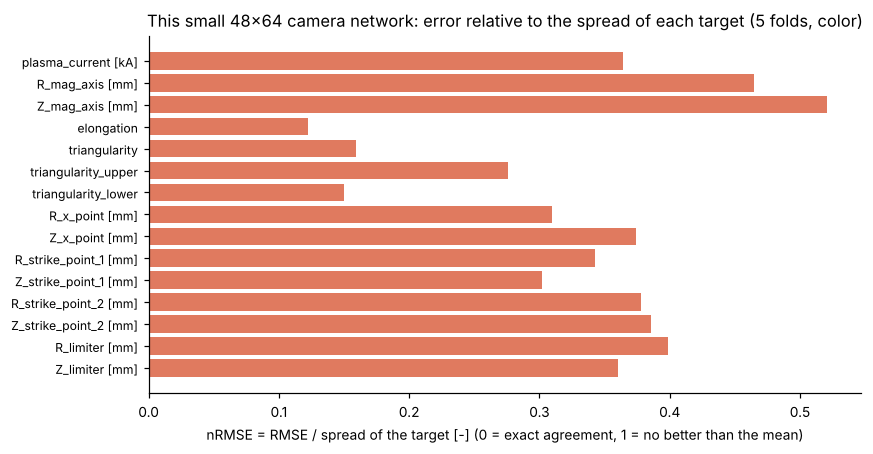

smallest relative error: elongation (0.122); largest: Z_mag_axis (0.521)


In [4]:
fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(TARGETS))
ax.barh(y, t_main.loc[TARGETS, "rgb nRMSE"], color=C_CAM)
ax.set_yticks(y); ax.set_yticklabels([f"{t} [{UNIT[t]}]" if UNIT[t] else t for t in TARGETS], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("nRMSE = RMSE / spread of the target [-] (0 = exact agreement, 1 = no better than the mean)")
ax.set_title("This small 48x64 camera network: error relative to the spread of each target (5 folds, color)")
plt.tight_layout(); plt.show()
best = t_main.loc[TARGETS, "rgb nRMSE"].idxmin(); worst = t_main.loc[TARGETS, "rgb nRMSE"].idxmax()
print(f"smallest relative error: {best} ({t_main.loc[best,'rgb nRMSE']:.3f}); largest: {worst} ({t_main.loc[worst,'rgb nRMSE']:.3f})")

## 3. Learning curve: how many training discharges does this small camera network need?

Same network, same 5 test folds, nested random subsets of each fold's training discharges (color frames). The number of
epochs is fixed, so the smaller subsets also receive fewer optimizer updates; part of the slope is therefore more updates, not
only more data.

MAE of this small 48x64 camera network (color) against the number of training discharges (mean over 5 folds)
                     4 discharges  7 discharges  16 discharges  31 discharges  62 discharges
R_mag_axis [mm]            4.8900         3.890         2.7400         2.3500          1.790
Z_mag_axis [mm]            5.6900         5.300         4.2200         3.3300          2.480
elongation                 0.0657         0.046         0.0346         0.0236          0.016
R_x_point [mm]             4.5100         3.760         2.9100         2.2800          1.540
R_limiter [mm]            46.4000        32.300        23.4000        16.8000         12.800
plasma_current [kA]       37.7000        33.600        31.5000        24.9000         14.600
is_limited, share of rows that agree with the reference reconstruction: 0.924, 0.936, 0.961, 0.966, 0.976


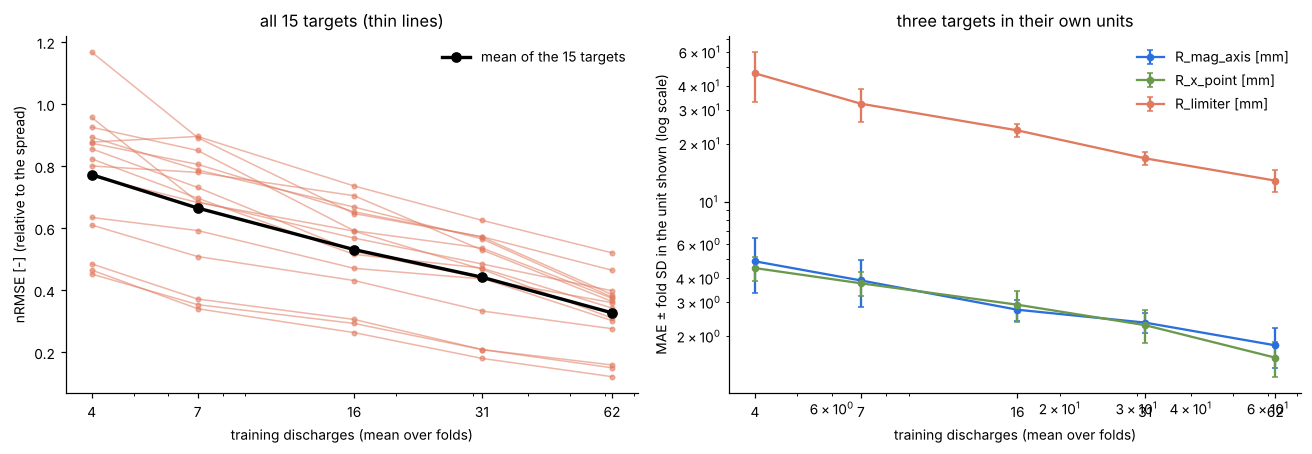

from 31 to 62 training discharges the MAE still falls for 15 of 15 targets, by 23 to 41 % (median 31 %)


In [5]:
t_curve = load_md_table("cloud-camera-curve.md")
FR = ["fraction_0.05", "fraction_0.1", "fraction_0.25", "fraction_0.5", "fraction_1"]
NTRAIN = [curve["training"][f]["discharges"] for f in FR]
# cross-check md against json, and the full-data point against the 'main' run (same network, same folds)
for t in t_curve.index:
    for f in FR:
        assert abs(t_curve.loc[t, f"{f} MAE"] - curve["results"][f][t]["mae"]) <= 0.006 * abs(curve["results"][f][t]["mae"]) + 1e-9
    assert abs(curve["results"]["fraction_1"][t]["mae"] - main["results"]["rgb"][t]["mae"]) <= 0.03 * abs(main["results"]["rgb"][t]["mae"]) + 1e-6, t

show = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter", "plasma_current"]
tab = pd.DataFrame({f"{n:.0f} discharges": [t_curve.loc[t, f"{f} MAE"] for t in show] for n, f in zip(NTRAIN, FR)},
                   index=[f"{t} [{UNIT[t]}]" if UNIT[t] else t for t in show])
print("MAE of this small 48x64 camera network (color) against the number of training discharges (mean over 5 folds)")
print(tab.to_string())
acc = [curve["results"][f]["is_limited"]["accuracy"] for f in FR]
print("is_limited, share of rows that agree with the reference reconstruction:", ", ".join(f"{a:.3f}" for a in acc))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for t in TARGETS:
    ax[0].plot(NTRAIN, [curve["results"][f][t]["nrmse"] for f in FR], marker="o", ms=3, lw=1, color=C_CAM, alpha=0.55)
ax[0].plot(NTRAIN, [np.mean([curve["results"][f][t]["nrmse"] for t in TARGETS]) for f in FR], color="k", lw=2.2, marker="o", label=f"mean of the {len(TARGETS)} targets")
ax[0].set_xscale("log"); ax[0].set_xticks(NTRAIN); ax[0].set_xticklabels([f"{n:.0f}" for n in NTRAIN])
ax[0].xaxis.set_minor_formatter(plt.NullFormatter()); ax[1].xaxis.set_minor_formatter(plt.NullFormatter())
ax[0].set_xlabel("training discharges (mean over folds)"); ax[0].set_ylabel("nRMSE [-] (relative to the spread)")
ax[0].set_title(f"all {len(TARGETS)} targets (thin lines)"); ax[0].legend(frameon=False)
for t, c in (("R_mag_axis", C_MAG), ("R_x_point", C_BOTH), ("R_limiter", C_CAM)):
    v = np.array([curve["results"][f][t]["mae"] for f in FR]); s = np.array([curve["results"][f][t]["mae_std"] for f in FR])
    ax[1].errorbar(NTRAIN, v, yerr=s, marker="o", ms=4, capsize=2, color=c, label=f"{t} [{UNIT[t]}]")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xticks(NTRAIN); ax[1].set_xticklabels([f"{n:.0f}" for n in NTRAIN])
ax[1].set_xlabel("training discharges (mean over folds)"); ax[1].set_ylabel("MAE ± fold SD in the unit shown (log scale)")
ax[1].set_title("three targets in their own units"); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

drop = {t: 1 - curve["results"]["fraction_1"][t]["mae"] / curve["results"]["fraction_0.5"][t]["mae"] for t in TARGETS}
n31, n62 = NTRAIN[3], NTRAIN[4]
print(f"from {n31:.0f} to {n62:.0f} training discharges the MAE still falls for {sum(d > 0 for d in drop.values())} of {len(TARGETS)} targets, "
      f"by {min(drop.values())*100:.0f} to {max(drop.values())*100:.0f} % (median {np.median(list(drop.values()))*100:.0f} %)")

Reading the curve: the error is still falling at the largest size, so we see no plateau in the tested range. Because the number of epochs is fixed, the smaller subsets
also get fewer updates, so part of the slope is more training steps and the curve does not show that more discharges alone would help. It does not say how it would look beyond the
discharges that have frames either; that is an extrapolation we do not make. No magnetic learning curve is drawn here: the magnetic one uses other discharges and
rows, so putting it next to this one would not be like for like (see `results/ipp1-robustness-findings.md`, section 2).

## 4. Color against black and white (REQ-B03)

The same network trained on color frames and on gray frames, same folds and seed. A difference counts only if it is larger
than the fold-to-fold SD of the MAE.

                    unit  color_MAE  gray_MAE  gray_minus_color  gap_over_fold_SD
target                                                                           
plasma_current        kA    14.6014   14.0342           -0.5672           -0.0877
R_mag_axis            mm     1.7879    1.7039           -0.0840           -0.1989
Z_mag_axis            mm     2.4786    2.4020           -0.0766           -0.1049
elongation             -     0.0160    0.0162            0.0002            0.0503
triangularity          -     0.0089    0.0085           -0.0004           -0.2827
triangularity_upper    -     0.0095    0.0089           -0.0006           -0.2860
triangularity_lower    -     0.0130    0.0125           -0.0005           -0.1739
R_x_point             mm     1.5428    1.5045           -0.0383           -0.0939
Z_x_point             mm     2.0494    2.1752            0.1258            0.1379
R_strike_point_1      mm     2.2711    2.2513           -0.0198           -0.0239
Z_strike_point_1

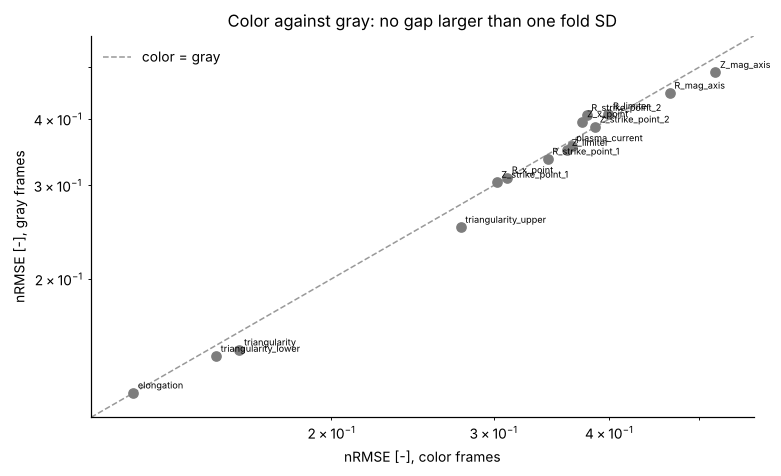

In [6]:
rows = []
for t in TARGETS:
    c, g = main["results"]["rgb"][t], main["results"]["grey"][t]
    gap = g["mae"] - c["mae"]
    rows.append(dict(target=t, unit=UNIT[t] or "-", color_MAE=c["mae"], gray_MAE=g["mae"], gray_minus_color=gap,
                     gap_over_fold_SD=gap / max(c["mae_std"], g["mae_std"])))
cg = pd.DataFrame(rows).set_index("target")
print(cg.round(4).to_string())
n_unres = int((cg["gap_over_fold_SD"].abs() < 1).sum())
print(f"\n{n_unres} of {len(TARGETS)} targets differ by less than one fold SD; the largest gap is {cg['gap_over_fold_SD'].abs().max():.2f} fold SD "
      f"({cg['gap_over_fold_SD'].abs().idxmax()}). is_limited, share of rows that agree with the reference reconstruction: color {float(ACC_MAIN['rgb']):.3f}, gray {float(ACC_MAIN['grey']):.3f}")
lat = main["latency"]
print(f"model time per frame (CPU, median, model only): color {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms, gray {lat['grey']['single_frame_cpu_ms_median']:.2f} ms")

fig, ax = plt.subplots(figsize=(7.2, 4.4))
lim = [min(t_main.loc[TARGETS, "rgb nRMSE"].min(), t_main.loc[TARGETS, "grey nRMSE"].min()) * 0.9,
       max(t_main.loc[TARGETS, "rgb nRMSE"].max(), t_main.loc[TARGETS, "grey nRMSE"].max()) * 1.1]
ax.plot(lim, lim, color="#999", lw=1, ls="--", label="color = gray")
ax.scatter(t_main.loc[TARGETS, "rgb nRMSE"], t_main.loc[TARGETS, "grey nRMSE"], color=C_GREY, zorder=3)
for t in TARGETS:
    ax.annotate(t, (t_main.loc[t, "rgb nRMSE"], t_main.loc[t, "grey nRMSE"]), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("nRMSE [-], color frames"); ax.set_ylabel("nRMSE [-], gray frames"); ax.legend(frameon=False)
ax.set_title("Color against gray: " + ("no gap larger than one fold SD" if n_unres == len(TARGETS) else f"{len(TARGETS) - n_unres} gaps larger than one fold SD"))
plt.tight_layout(); plt.show()

## 5. This small camera network against the magnetic network, on the same frames and folds (REQ-B01)

Three models, trained on exactly the same frames (section 1) and tested on the same discharges in each fold:

- **magnetic**: the baseline MLP (`fit_mlp`, 60 epochs) fed the 24 coil signals interpolated to those frames;
- **camera**: this small 48x64 camera network (picture only);
- **camera + magnetic**: one network that takes the picture and the 24 coil signals.

This magnetic comparison model is trained on only the frames of the discharges that have a camera, so it is weaker than the baseline of notebook 02
(which trains on about 119 discharges). That is the price of the like-for-like comparison.

MAE in the unit shown, mean over the same 5 folds and the same frames (columns 'magnetic', 'camera', 'camera_plus_magnetic')
                    unit  magnetic   camera  camera_plus_magnetic  camera_over_magnetic  both_over_magnetic
target                                                                                                     
plasma_current        kA    1.4700  14.6000                2.3000                9.9320              1.5646
R_mag_axis            mm    0.5890   1.7900                1.5400                3.0390              2.6146
Z_mag_axis            mm    0.4950   2.4800                1.1300                5.0101              2.2828
elongation             -    0.0077   0.0160                0.0131                2.0752              1.6991
triangularity          -    0.0039   0.0090                0.0069                2.3127              1.7829
triangularity_upper    -    0.0034   0.0095                0.0064                2.7449              1.8667
triangulari

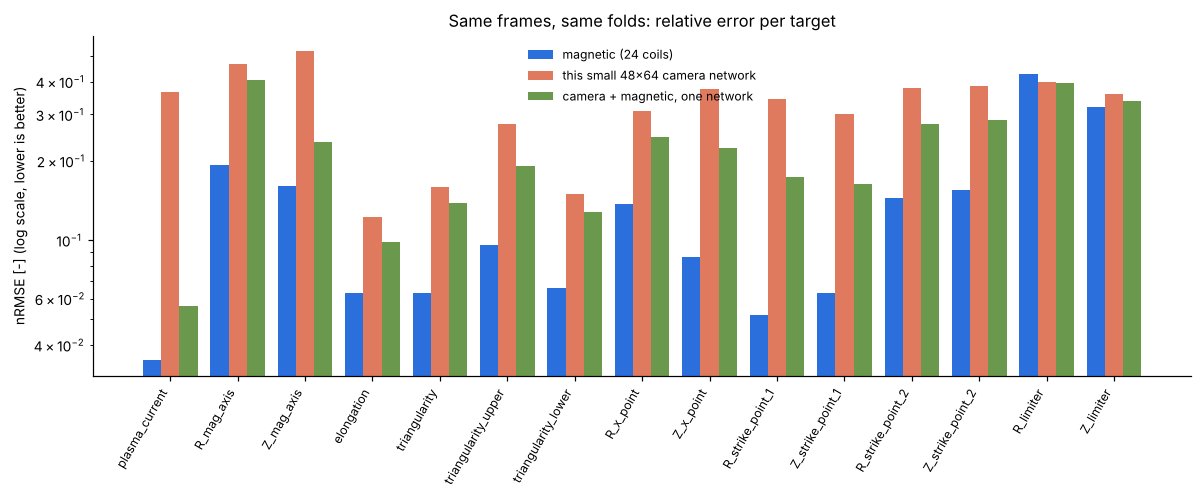

In [7]:
t_mm = load_md_table("cloud-camera-multimodal.md")
acc_mm = dict(re.findall(r"(magnetic|camera\+magnetic|camera) ([0-9.]+)", load_md_line("cloud-camera-multimodal.md", "is_limited accuracy")))
for t in t_mm.index:
    for key, col in (("magnetic", "magnetic"), ("camera", "camera"), ("camera+magnetic", "camera+magnetic")):
        j = multi["results"][key][t]["mae"]
        assert abs(t_mm.loc[t, f"{col} MAE"] - j) <= 0.006 * abs(j) + 1e-9, (t, key)

def msd(key, t):
    return multi["results"][key][t]["mae_std"]

rows = []
for t in TARGETS:
    m, c, b = (t_mm.loc[t, f"{k} MAE"] for k in ("magnetic", "camera", "camera+magnetic"))
    rows.append(dict(target=t, unit=UNIT[t] or "-", magnetic=m, camera=c, camera_plus_magnetic=b,
                     camera_over_magnetic=c / m, both_over_magnetic=b / m,
                     nRMSE_magnetic=t_mm.loc[t, "magnetic nRMSE"], nRMSE_camera=t_mm.loc[t, "camera nRMSE"], nRMSE_both=t_mm.loc[t, "camera+magnetic nRMSE"]))
cmp_ = pd.DataFrame(rows).set_index("target")
print("MAE in the unit shown, mean over the same 5 folds and the same frames (columns 'magnetic', 'camera', 'camera_plus_magnetic')")
print(cmp_[["unit", "magnetic", "camera", "camera_plus_magnetic", "camera_over_magnetic", "both_over_magnetic"]].round(4).to_string())
print(f"\nis_limited, share of rows that agree with the reference reconstruction: magnetic {float(acc_mm['magnetic']):.3f}, camera {float(acc_mm['camera']):.3f}, camera+magnetic {float(acc_mm['camera+magnetic']):.3f}")

fig, ax = plt.subplots(figsize=(11, 4.6))
x = np.arange(len(TARGETS)); w = 0.27
for i, (k, col, lab) in enumerate((("magnetic", C_MAG, "magnetic (24 coils)"), ("camera", C_CAM, "this small 48x64 camera network"), ("camera+magnetic", C_BOTH, "camera + magnetic, one network"))):
    ax.bar(x + (i - 1) * w, [t_mm.loc[t, f"{k} nRMSE"] for t in TARGETS], w, color=col, label=lab)
ax.set_yscale("log"); ax.set_xticks(x); ax.set_xticklabels(TARGETS, rotation=60, ha="right", fontsize=8)
ax.set_ylabel("nRMSE [-] (log scale, lower is better)")
ax.set_title("Same frames, same folds: relative error per target"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

In [8]:
# which model is better on each target, and is the gap larger than the fold SD of both models?
def clear_winner(t, a, b):
    ma, mb = multi["results"][a][t]["mae"], multi["results"][b][t]["mae"]
    return (ma < mb) and (mb - ma > max(msd(a, t), msd(b, t)))

cam_beats_mag = [t for t in TARGETS if cmp_.loc[t, "camera"] < cmp_.loc[t, "magnetic"]]
cam_clear = [t for t in TARGETS if clear_winner(t, "camera", "magnetic")]
mag_clear = [t for t in TARGETS if clear_winner(t, "magnetic", "camera")]
both_beats_mag = [t for t in TARGETS if cmp_.loc[t, "camera_plus_magnetic"] < cmp_.loc[t, "magnetic"]]
both_clear_mag = [t for t in TARGETS if clear_winner(t, "camera+magnetic", "magnetic")]
mag_clear_both = [t for t in TARGETS if clear_winner(t, "magnetic", "camera+magnetic")]
both_beats_cam_lim = [t for t in ("R_limiter", "Z_limiter") if clear_winner(t, "camera+magnetic", "camera")]
ratio_nr = (cmp_["nRMSE_camera"] / cmp_["nRMSE_magnetic"]).drop(["R_limiter", "Z_limiter"])
print(f"camera has the lower MAE than the magnetic network on {len(cam_beats_mag)} of {len(TARGETS)} targets: {cam_beats_mag}")
print(f"  ... and the gap exceeds the fold SD of both models on: {cam_clear}")
print(f"magnetic is clearly better (gap > both fold SD) on {len(mag_clear)} targets; on the other {len(TARGETS) - len(mag_clear) - len(cam_clear)} the two are not separated")
print(f"on the {len(ratio_nr)} targets other than the limiter point the camera nRMSE is {ratio_nr.min():.1f} to {ratio_nr.max():.1f} times the magnetic nRMSE")
print(f"camera + magnetic in one network beats magnetic alone on {len(both_beats_mag)} targets {both_beats_mag}, clearly on {both_clear_mag}")
print(f"magnetic alone clearly beats camera + magnetic on {len(mag_clear_both)} targets: {mag_clear_both}")
print(f"camera + magnetic clearly beats the camera alone at the limiter point on: {both_beats_cam_lim or 'neither limiter target'}")

camera has the lower MAE than the magnetic network on 2 of 15 targets: ['R_limiter', 'Z_limiter']
  ... and the gap exceeds the fold SD of both models on: ['R_limiter']
magnetic is clearly better (gap > both fold SD) on 13 targets; on the other 1 the two are not separated
on the 13 targets other than the limiter point the camera nRMSE is 1.9 to 10.4 times the magnetic nRMSE
camera + magnetic in one network beats magnetic alone on 2 targets ['R_limiter', 'Z_limiter'], clearly on ['R_limiter']
magnetic alone clearly beats camera + magnetic on 13 targets: ['plasma_current', 'R_mag_axis', 'Z_mag_axis', 'elongation', 'triangularity', 'triangularity_upper', 'triangularity_lower', 'R_x_point', 'Z_x_point', 'R_strike_point_1', 'Z_strike_point_1', 'R_strike_point_2', 'Z_strike_point_2']
camera + magnetic clearly beats the camera alone at the limiter point on: neither limiter target


**Fusion by weighted late combination, realistic (noisy) coil signals, the discharges set aside before the final choice, training with shifts, and an
occlusion map** were planned in `analysis/cloud_camera_fusion.py` and `analysis/cloud_camera_explain.py`. The next cell
checks which of them have a result file committed in git, so that this notebook says "not available" instead of leaving the
gap silent.

In [9]:
KNOWN = {"main", "multimodal", "curve"}
PLANNED = {
    "weighted late fusion with the magnetic network": "cloud_camera_fusion.py",
    "camera against noisy coil signals (equil_data_noisy.csv inputs)": "cloud_camera_fusion.py",
    "scored on the discharges set aside before the final choice (those that have frames)": "cloud_camera_fusion.py --locked",
    "training with random shifts and rotations (REQ-B05 fix)": "cloud_camera_model.py augment",
    "occlusion map / which image parts matter (REQ-B07)": "cloud_camera_explain.py",
}
extra = {}
for p in sorted(RES.glob("cloud-camera-*.json")):
    d = load_json(p.name)
    if d.get("experiment") not in KNOWN:
        extra[p.name] = d.get("experiment")
if extra:
    print("further camera result files found in git:", extra)
    for name in extra:
        md_name = name.replace(".json", ".md")
        if (RES / md_name).exists():
            READ.append(f"results/{md_name}")
            display(Markdown((RES / md_name).read_text(encoding="utf-8")))
else:
    print("No further camera result file is committed in git. Not available here (no number is shown for them):")
    for k, v in PLANNED.items():
        print(f"  - {k}   [script: {v}]")

No further camera result file is committed in git. Not available here (no number is shown for them):
  - weighted late fusion with the magnetic network   [script: cloud_camera_fusion.py]
  - camera against noisy coil signals (equil_data_noisy.csv inputs)   [script: cloud_camera_fusion.py]
  - scored on the discharges set aside before the final choice (those that have frames)   [script: cloud_camera_fusion.py --locked]
  - training with random shifts and rotations (REQ-B05 fix)   [script: cloud_camera_model.py augment]
  - occlusion map / which image parts matter (REQ-B07)   [script: cloud_camera_explain.py]


## 6. A camera that moves (REQ-B05)

This small camera network was trained on the unmoved image and tested on test frames shifted by 1, 2 or 4 cached pixels
(one cached pixel is 1/64 of the frame width) in x or y, or rotated about the image center by 1, 2 or 5 degrees. The ratio is
the MAE on the moved frames divided by the MAE on the unmoved frames of the same network (color; the gray network behaves
the same, as the next cell checks). A model *trained* with random shifts is not available (see the cell above).

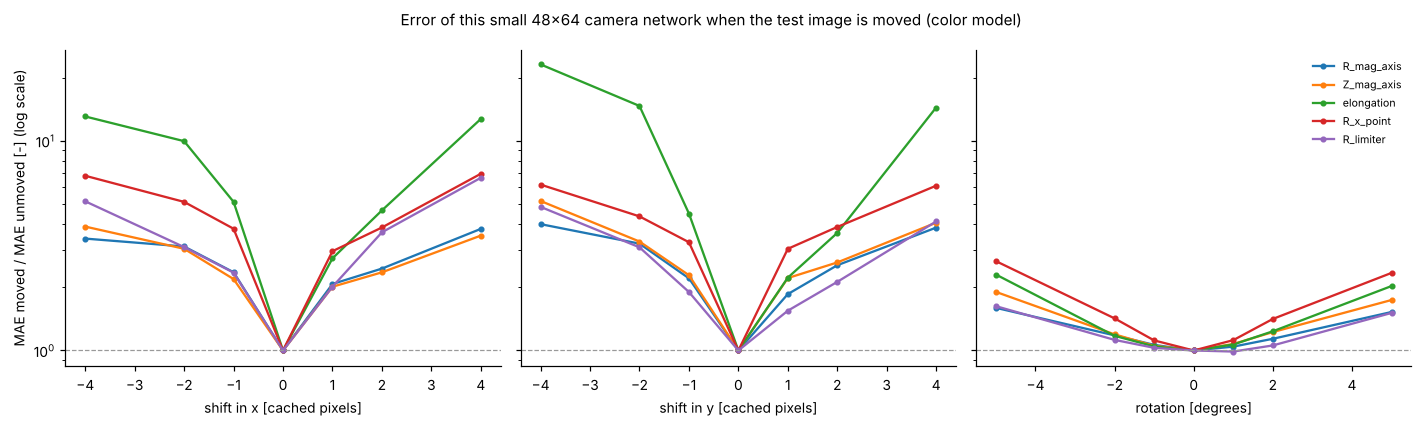

worst ratio over directions (shift: x and y, + and -; rotate: + and -), color model
            shift 1  shift 4  rotate 1  rotate 2  rotate 5
R_mag_axis     2.36     4.01      1.06      1.18      1.60
Z_mag_axis     2.29     5.17      1.07      1.22      1.90
elongation     5.12    23.16      1.07      1.23      2.30
R_x_point      3.81     6.97      1.12      1.42      2.67
R_limiter      2.35     6.66      1.03      1.12      1.63
is_limited, share of rows that agree with the reference reconstruction: {'clean': 0.975, 'shift_x=+1': 0.962, 'shift_x=+4': 0.738, 'rotate=+5': 0.966}
gray against color, 1 pixel shift: median relative difference of the worst-case ratio 5 %


In [10]:
sw = main["sweeps"]
SENS = ["R_mag_axis", "Z_mag_axis", "elongation", "R_x_point", "R_limiter"]
def ratio(chan, key, t):
    return sw[chan][key][t]["mae"] / sw[chan]["clean"][t]["mae"]

shifts = [-4, -2, -1, 1, 2, 4]
rots = [-5, -2, -1, 1, 2, 5]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.9), sharey=True)
for a, (ttl, keyf, xs) in zip(ax, (("shift in x [cached pixels]", lambda s: f"shift_x={s:+d}", shifts),
                                   ("shift in y [cached pixels]", lambda s: f"shift_y={s:+d}", shifts),
                                   ("rotation [degrees]", lambda s: f"rotate={s:+d}", rots))):
    for t in SENS:
        xx = sorted(xs + [0])
        a.plot(xx, [1.0 if s == 0 else ratio("rgb", keyf(s), t) for s in xx], marker="o", ms=3, label=t)
    a.axhline(1, color="#999", lw=0.8, ls="--"); a.set_yscale("log"); a.set_xlabel(ttl)
ax[0].set_ylabel("MAE moved / MAE unmoved [-] (log scale)"); ax[2].legend(frameon=False, fontsize=7)
fig.suptitle("Error of this small 48x64 camera network when the test image is moved (color model)", fontsize=10)
plt.tight_layout(); plt.show()

def worst(chan, kind, mag):
    if kind == "shift":
        keys = [f"shift_{ax_}={s:+d}" for ax_ in "xy" for s in (-mag, mag)]
    else:
        keys = [f"rotate={s:+d}" for s in (-mag, mag)]
    return {t: max(ratio(chan, k, t) for k in keys) for t in TARGETS}

tab = pd.DataFrame({f"{kind} {mag}": worst("rgb", kind, mag) for kind, mag in (("shift", 1), ("shift", 4), ("rotate", 1), ("rotate", 2), ("rotate", 5))})
print("worst ratio over directions (shift: x and y, + and -; rotate: + and -), color model")
print(tab.loc[SENS].round(2).to_string())
# the reading below is checked here, not typed from memory
assert (tab.loc[SENS, "shift 1"] > 2).all() and (tab.loc[SENS, "rotate 2"] < tab.loc[SENS, "shift 1"]).all()
acc_s = {k: sw["rgb"][k]["is_limited"]["accuracy"] for k in ("clean", "shift_x=+1", "shift_x=+4", "rotate=+5")}
print("is_limited, share of rows that agree with the reference reconstruction:", {k: round(v, 3) for k, v in acc_s.items()})
grey_same = np.median([abs(np.log(worst("grey", "shift", 1)[t] / worst("rgb", "shift", 1)[t])) for t in TARGETS])
print(f"gray against color, 1 pixel shift: median relative difference of the worst-case ratio {np.expm1(grey_same)*100:.0f} %")

Reading: this network estimates absolute positions in the picture, so a camera that moves looks like a plasma that moves.
In the table above a shift of one cached pixel already multiplies the error of every target shown by more than two, the shape
parameters suffer most, and a rotation of 2 degrees matters much less than a shift of one pixel. Whether a network trained with random shifts removes the effect is not
measured in the committed results.

## 7. Cost at run time

In [11]:
lat = main["latency"]
mag_ms = base["latency"]["single_sample_cpu_ms_median"]
print("model time per input, CPU, median, model only (no JPEG reading, no decoding, no coil acquisition); different machines/runs:")
for chan, name in (("rgb", "this small 48x64 camera network, color"), ("grey", "this small 48x64 camera network, gray")):
    print(f"  {name:45s} {lat[chan]['single_frame_cpu_ms_median']:.2f} ms (p99 {lat[chan]['single_frame_cpu_ms_p99']:.2f} ms), {lat[chan]['parameters']:,} parameters")
print(f"  {'magnetic baseline MLP (results/ipp1-baseline.json)':45s} {mag_ms:.4f} ms (p99 {base['latency']['single_sample_cpu_ms_p99']:.3f} ms), {base['latency']['parameters']:,} parameters")
print(f"  ratio camera (color) / magnetic: about {lat['rgb']['single_frame_cpu_ms_median'] / mag_ms:.0f}")
cam_ms = lat["rgb"]["single_frame_cpu_ms_median"]
where = "inside" if cam_ms <= 1 else ("above the 1 ms end and below the 10 ms end of" if cam_ms < 10 else "above")
print(f"Against the 1 to 10 ms budget: the magnetic network ({mag_ms:.4f} ms) is far inside it; the camera network ({cam_ms:.2f} ms median, p99 {lat['rgb']['single_frame_cpu_ms_p99']:.2f} ms) is {where} the budget. "
      "The CPU and its load are not recorded in the result files; reading, decoding and the worst case on a real-time system were not measured, so the verdict for the control loop is conditional, as in notebook 05, and open for the camera.")

model time per input, CPU, median, model only (no JPEG reading, no decoding, no coil acquisition); different machines/runs:
  this small 48x64 camera network, color        1.69 ms (p99 2.97 ms), 811,328 parameters
  this small 48x64 camera network, gray         1.34 ms (p99 2.78 ms), 811,040 parameters
  magnetic baseline MLP (results/ipp1-baseline.json) 0.0148 ms (p99 0.042 ms), 107,152 parameters
  ratio camera (color) / magnetic: about 114
Against the 1 to 10 ms budget: the magnetic network (0.0148 ms) is far inside it; the camera network (1.69 ms median, p99 2.97 ms) is above the 1 ms end and below the 10 ms end of the budget. The CPU and its load are not recorded in the result files; reading, decoding and the worst case on a real-time system were not measured, so the verdict for the control loop is conditional, as in notebook 05, and open for the camera.


## 8. Provenance of every file read

In [12]:
tracked = None
try:
    tracked = set(subprocess.run(["git", "ls-files", "results"], cwd=repo, capture_output=True, text=True, check=True).stdout.split())
except Exception as e:                                           # git missing in the sandbox: say so instead of passing silently
    print("git ls-files unavailable:", type(e).__name__)
for f in sorted(set(READ)):
    print(f"{f:50s} {'tracked in git' if tracked is not None and f in tracked else ('NOT TRACKED' if tracked is not None else 'not checked')}")
if tracked is not None:
    assert all(f in tracked for f in READ), "a file outside git was read"
print("\nNo image, no raw row of equil_data.csv and no file outside git was opened.")

results/cloud-camera-curve.json                    tracked in git
results/cloud-camera-curve.md                      tracked in git
results/cloud-camera-main.json                     tracked in git
results/cloud-camera-main.md                       tracked in git
results/cloud-camera-multimodal.json               tracked in git
results/cloud-camera-multimodal.md                 tracked in git
results/ipp1-baseline.json                         tracked in git

No image, no raw row of equil_data.csv and no file outside git was opened.


## Answer

In [13]:
n_t = len(TARGETS)
lo, hi = ratio_nr.min(), ratio_nr.max()
cur_c, cur_m = cmp_.loc["plasma_current"], None
sh1 = worst("rgb", "shift", 1)
rot2 = worst("rgb", "rotate", 2)
R = cmp_.loc["R_limiter"]; Z = cmp_.loc["Z_limiter"]
txt = f'''
**Does the optional camera help?** On clean coil signals and on the same frames and folds, **this small 48x64 camera network
does not beat the magnetic network on {n_t - len(cam_beats_mag)} of the {n_t} targets**; on the {len(ratio_nr)} targets other than the limiter
point its relative error (nRMSE) is {lo:.1f} to {hi:.1f} times larger. Examples (MAE against the reference reconstruction, mean over {main['folds']} folds): R of the magnetic axis
{cmp_.loc['R_mag_axis','camera']:.2f} mm against {cmp_.loc['R_mag_axis','magnetic']:.2f} mm, plasma current
{cmp_.loc['plasma_current','camera']:.1f} kA against {cmp_.loc['plasma_current','magnetic']:.2f} kA. The largest gap is on {ratio_nr.idxmax()} ({ratio_nr.max():.1f} times in nRMSE). A possible reason (not tested here) is that the picture shows the light of the
plasma edge, not the magnetic fluxes.

**Where it does better.** At the limiter point, where the plasma touches the wall that the picture shows, the MAE of R is
{R['camera']:.1f} mm for the camera network against {R['magnetic']:.1f} mm for the magnetic network
({'larger than the fold SD of both models' if 'R_limiter' in cam_clear else 'within the fold SD, so not separated'}); for Z it is {Z['camera']:.1f} mm against
{Z['magnetic']:.1f} mm ({'larger than the fold SD of both models' if 'Z_limiter' in cam_clear else 'within the fold SD, so not separated'}). Both are large errors in absolute terms, because the limiter point is a
discrete wall contact.

**Does feeding both inputs help?** One network that takes the picture and the 24 coil signals beats the magnetic network alone on
{len(both_beats_mag)} of {n_t} targets (clearly, by more than the fold SD, on {len(both_clear_mag)}) and is clearly worse on {len(mag_clear_both)}. This is a
statement about that one small fusion design trained for {main['epochs']} epochs, not proof that the picture carries no extra information.
The fusion with realistic (noisy) coil signals, a weighted late fusion and the discharges set aside before the final choice are not available in the
committed results, so we make **no claim** about the camera as a back-up when the coils are noisy.

**Color or black and white?** No difference that we can resolve: {n_unres} of {n_t} targets differ by less than one fold SD and the
largest gap is {cg['gap_over_fold_SD'].abs().max():.2f} fold SD. For this network black and white frames do as well as color on these targets, and the forward
pass is a little faster ({lat['grey']['single_frame_cpu_ms_median']:.2f} against {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms).

**How much data does it need?** We cannot say. From {n31:.0f} to {n62:.0f} training discharges the MAE still fell by a median of
{np.median(list(drop.values()))*100:.0f} % across the targets, with no plateau in the tested range; because the number of epochs is fixed, part of that fall is more training updates, not only more data. Only {main['discharges']} of the 149 discharges have frames.

**What breaks it?** A moving camera. A shift of one cached pixel (1/64 of the frame width) multiplies the error by up to
{sh1['R_mag_axis']:.1f} on the R of the axis and {sh1['elongation']:.1f} on the elongation; a 2 degree rotation by up to {rot2['R_mag_axis']:.2f} and {rot2['elongation']:.2f}. The
camera must be fixed and calibrated, or the network trained with shifts, which is not measured here.

**Speed.** {lat['rgb']['single_frame_cpu_ms_median']:.2f} ms per frame on a CPU for the network alone, about {lat['rgb']['single_frame_cpu_ms_median'] / mag_ms:.0f} times the magnetic MLP
({mag_ms:.3f} ms). Against the 1 to 10 ms budget the camera network's median is {where} the budget (CPU and load not recorded in the result file). Reading and decoding the image and the worst case on a real-time system were not timed, so the verdict stays conditional.

**In plain words.** In this comparison the 24 magnetic coils are the better source for shape and position, and one network that sees both inputs is clearly better than the magnetic network alone only on {', '.join(both_clear_mag) or 'no target'}. It is an interesting second opinion, not a replacement.

**Limits.** 78 discharges with frames, 15 or 16 test discharges per fold, one seed per fold, the fold SD is {rel.min()*100:.0f} to
{rel.max()*100:.0f} % of the MAE, every {main['stride']}th frame, frames of {main['size']} pixels (a higher resolution or a pretrained backbone is
untested), the magnetic comparison model here is trained on the same frames only, so it is weaker than the baseline of notebook 02. The
result concerns this network, not every possible camera model. All targets are the institute's reference reconstruction interpolated to the frame times, not an independent measurement of the plasma, so no statement is made about the camera against the plasma itself.
'''
display(Markdown(txt))


**Does the optional camera help?** On clean coil signals and on the same frames and folds, **this small 48x64 camera network
does not beat the magnetic network on 13 of the 15 targets**; on the 13 targets other than the limiter
point its relative error (nRMSE) is 1.9 to 10.4 times larger. Examples (MAE against the reference reconstruction, mean over 5 folds): R of the magnetic axis
1.79 mm against 0.59 mm, plasma current
14.6 kA against 1.47 kA. The largest gap is on plasma_current (10.4 times in nRMSE). A possible reason (not tested here) is that the picture shows the light of the
plasma edge, not the magnetic fluxes.

**Where it does better.** At the limiter point, where the plasma touches the wall that the picture shows, the MAE of R is
12.8 mm for the camera network against 16.7 mm for the magnetic network
(larger than the fold SD of both models); for Z it is 28.8 mm against
30.4 mm (within the fold SD, so not separated). Both are large errors in absolute terms, because the limiter point is a
discrete wall contact.

**Does feeding both inputs help?** One network that takes the picture and the 24 coil signals beats the magnetic network alone on
2 of 15 targets (clearly, by more than the fold SD, on 1) and is clearly worse on 13. This is a
statement about that one small fusion design trained for 12 epochs, not proof that the picture carries no extra information.
The fusion with realistic (noisy) coil signals, a weighted late fusion and the discharges set aside before the final choice are not available in the
committed results, so we make **no claim** about the camera as a back-up when the coils are noisy.

**Color or black and white?** No difference that we can resolve: 15 of 15 targets differ by less than one fold SD and the
largest gap is 0.29 fold SD. For this network black and white frames do as well as color on these targets, and the forward
pass is a little faster (1.34 against 1.69 ms).

**How much data does it need?** We cannot say. From 31 to 62 training discharges the MAE still fell by a median of
31 % across the targets, with no plateau in the tested range; because the number of epochs is fixed, part of that fall is more training updates, not only more data. Only 78 of the 149 discharges have frames.

**What breaks it?** A moving camera. A shift of one cached pixel (1/64 of the frame width) multiplies the error by up to
2.4 on the R of the axis and 5.1 on the elongation; a 2 degree rotation by up to 1.18 and 1.23. The
camera must be fixed and calibrated, or the network trained with shifts, which is not measured here.

**Speed.** 1.69 ms per frame on a CPU for the network alone, about 114 times the magnetic MLP
(0.015 ms). Against the 1 to 10 ms budget the camera network's median is above the 1 ms end and below the 10 ms end of the budget (CPU and load not recorded in the result file). Reading and decoding the image and the worst case on a real-time system were not timed, so the verdict stays conditional.

**In plain words.** In this comparison the 24 magnetic coils are the better source for shape and position, and one network that sees both inputs is clearly better than the magnetic network alone only on R_limiter. It is an interesting second opinion, not a replacement.

**Limits.** 78 discharges with frames, 15 or 16 test discharges per fold, one seed per fold, the fold SD is 4 to
46 % of the MAE, every 8th frame, frames of 48x64 pixels (a higher resolution or a pretrained backbone is
untested), the magnetic comparison model here is trained on the same frames only, so it is weaker than the baseline of notebook 02. The
result concerns this network, not every possible camera model. All targets are the institute's reference reconstruction interpolated to the frame times, not an independent measurement of the plasma, so no statement is made about the camera against the plasma itself.
